# 05 - PyTorch opcional: MNIST con Dropout, L2 y Early Stopping

Este notebook es opcional según la guía. Los cuatro notebooks de TensorFlow/Keras cubren la ruta principal. Aquí se implementa la misma lógica con PyTorch y un ciclo de entrenamiento explícito.

## 1. Importar herramientas y semillas

In [ ]:
import copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

PyTorch: 2.11.0+cpu
Dispositivo: cpu


## 2. Cargar MNIST y hacer división estratificada Train/Dev/Test

In [ ]:
transform = transforms.ToTensor()  # convierte uint8 [0,255] a float [0,1]
train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)
labels = np.asarray(train_full.targets)
indices = np.arange(len(train_full))
idx_train, idx_dev = train_test_split(
    indices, test_size=0.20, random_state=SEED, stratify=labels
)
train_dataset = Subset(train_full, idx_train)
dev_dataset = Subset(train_full, idx_dev)

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=generator)
dev_loader = DataLoader(dev_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)
print("Train:", len(train_dataset), "Dev:", len(dev_dataset), "Test:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 460kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.74MB/s]


Train: 48000 Dev: 12000 Test: 10000


## 3. Definir la red

In [ ]:
class RedMNISTRegularizada(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.30)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        return self.fc2(x)  # logits: CrossEntropyLoss aplica log-softmax internamente

modelo = RedMNISTRegularizada().to(device)
criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=0.001, weight_decay=1e-4)
print(modelo)

RedMNISTRegularizada(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


## 4. Entrenar y monitorear Dev con Early Stopping

In [ ]:
def evaluar_loss_accuracy(modelo, loader):
    modelo.eval()
    total_loss, total, correctos = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = modelo(xb)
            loss = criterio(logits, yb)
            total_loss += loss.item() * len(yb)
            pred = logits.argmax(dim=1)
            correctos += (pred == yb).sum().item()
            total += len(yb)
    return total_loss / total, correctos / total

hist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
mejor_val_loss = float("inf")
mejores_pesos = copy.deepcopy(modelo.state_dict())
paciencia, espera, max_epochs = 2, 0, 20

for epoca in range(max_epochs):
    modelo.train()
    suma_loss, correctos, total = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizador.zero_grad()
        logits = modelo(xb)
        loss = criterio(logits, yb)
        loss.backward()              # backpropagation explícito
        optimizador.step()           # actualización de parámetros
        suma_loss += loss.item() * len(yb)
        correctos += (logits.argmax(dim=1) == yb).sum().item()
        total += len(yb)
    train_loss = suma_loss / total
    train_acc = correctos / total
    val_loss, val_acc = evaluar_loss_accuracy(modelo, dev_loader)
    hist["loss"].append(train_loss); hist["accuracy"].append(train_acc)
    hist["val_loss"].append(val_loss); hist["val_accuracy"].append(val_acc)
    print(f"Época {epoca+1:02d}: loss={train_loss:.4f}, acc={train_acc:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")
    if val_loss < mejor_val_loss:
        mejor_val_loss = val_loss
        mejores_pesos = copy.deepcopy(modelo.state_dict())
        espera = 0
    else:
        espera += 1
        if espera >= paciencia:
            print("Early stopping: la pérdida de Dev dejó de mejorar.")
            break
modelo.load_state_dict(mejores_pesos)
print("Épocas ejecutadas:", len(hist["loss"]))

Época 01: loss=0.3680, acc=0.8971, val_loss=0.1930, val_acc=0.9447
Época 02: loss=0.1772, acc=0.9491, val_loss=0.1340, val_acc=0.9616
Época 03: loss=0.1297, acc=0.9623, val_loss=0.1118, val_acc=0.9678
Época 04: loss=0.1059, acc=0.9677, val_loss=0.1007, val_acc=0.9708
Época 05: loss=0.0908, acc=0.9730, val_loss=0.0915, val_acc=0.9738
Época 06: loss=0.0795, acc=0.9761, val_loss=0.0892, val_acc=0.9728
Época 07: loss=0.0720, acc=0.9782, val_loss=0.0853, val_acc=0.9757
Época 08: loss=0.0665, acc=0.9794, val_loss=0.0784, val_acc=0.9773
Época 09: loss=0.0602, acc=0.9819, val_loss=0.0810, val_acc=0.9762
Época 10: loss=0.0572, acc=0.9826, val_loss=0.0756, val_acc=0.9781
Época 11: loss=0.0523, acc=0.9840, val_loss=0.0726, val_acc=0.9785
Época 12: loss=0.0503, acc=0.9840, val_loss=0.0735, val_acc=0.9787
Época 13: loss=0.0472, acc=0.9851, val_loss=0.0815, val_acc=0.9750
Early stopping: la pérdida de Dev dejó de mejorar.
Épocas ejecutadas: 13


## 5. Curvas Train/Dev

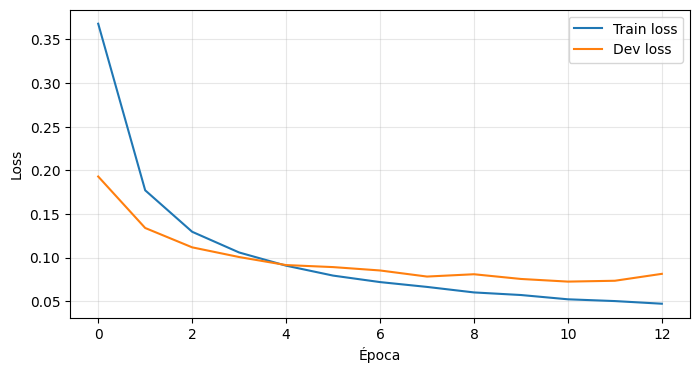

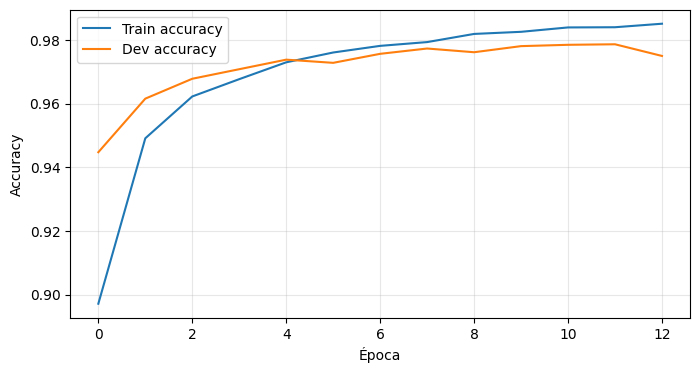

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["loss"], label="Train loss"); ax.plot(hist["val_loss"], label="Dev loss")
ax.set_xlabel("Época"); ax.set_ylabel("Loss"); ax.legend(); ax.grid(True, alpha=.3); plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["accuracy"], label="Train accuracy"); ax.plot(hist["val_accuracy"], label="Dev accuracy")
ax.set_xlabel("Época"); ax.set_ylabel("Accuracy"); ax.legend(); ax.grid(True, alpha=.3); plt.show()

## 6. Evaluación final en Test

Modelo guardado exitosamente.
Accuracy: 0.9806
Precision macro: 0.9806
Recall macro: 0.9804
F1 macro: 0.9805
              precision    recall  f1-score   support

           0     0.9828    0.9888    0.9858       980
           1     0.9877    0.9921    0.9899      1135
           2     0.9732    0.9845    0.9788      1032
           3     0.9822    0.9812    0.9817      1010
           4     0.9757    0.9807    0.9782       982
           5     0.9876    0.9787    0.9831       892
           6     0.9843    0.9802    0.9822       958
           7     0.9813    0.9679    0.9745      1028
           8     0.9814    0.9743    0.9778       974
           9     0.9704    0.9762    0.9733      1009

    accuracy                         0.9806     10000
   macro avg     0.9806    0.9804    0.9805     10000
weighted avg     0.9806    0.9806    0.9806     10000



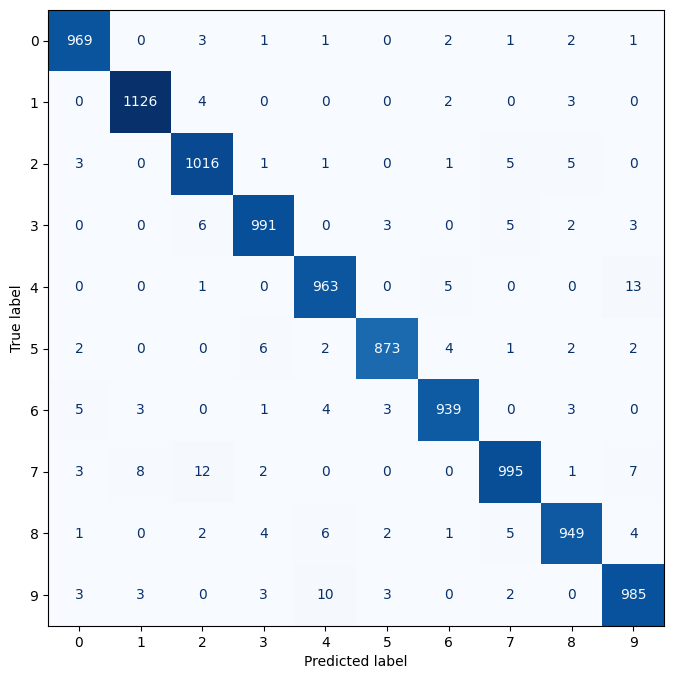

In [ ]:
modelo.eval()

import os

# Create the directory if it doesn't exist
os.makedirs("resultados", exist_ok=True)

torch.save(modelo.state_dict(), "resultados/modelo_pytorch_mnist.pth")
print("Modelo guardado exitosamente.")
y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        logits = modelo(xb.to(device))
        y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
        y_true.extend(yb.numpy().tolist())

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision macro:", round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Recall macro:", round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("F1 macro:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print(classification_report(y_true, y_pred, digits=4, zero_division=0))
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(ax=ax, cmap="Blues", colorbar=False)
plt.show()
torch.save(modelo.state_dict(), "resultados/modelo_pytorch_mnist.pth")

## 7. Interpretación

Compara conceptualmente con TensorFlow/Keras: Dropout(0.30), L2 por `weight_decay=1e-4`, Adam y parada según Dev. En PyTorch el ciclo hace explícitos `zero_grad()`, `loss.backward()` y `optimizer.step()`. Los resultados pueden no coincidir exactamente debido a las diferencias de implementación, inicialización y ejecución; analiza la tendencia y no afirmes igualdad exacta.